In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in 

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# Any results you write to the current directory are saved as output.

In [1]:
!pip install grad-cam -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np
import cv2
import os

In [3]:
class PyTorchGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Attach hooks to the layer
        self.forward_hook = target_layer.register_forward_hook(self.save_activation)
        self.backward_hook = target_layer.register_backward_hook(self.save_gradient)
        
    def save_activation(self, module, input, output):
        self.activations = output.detach()
        
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output.detach()
        
    def generate_cam(self, input_tensor, target_class):
        self.model.zero_grad()
        output = self.model(input_tensor)
        
        loss = output[0, target_class]
        loss.backward()
        
        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        
        cam = torch.clamp(cam, min=0)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-7)
        return cam.cpu().numpy()
        
    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()

In [ ]:
# Data transforms (augmentation, reshape, normalization)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),            # Reshape (standard input size for ResNet)
    transforms.RandomRotation(15),            # Augmentation (slight rotation)
    transforms.RandomHorizontalFlip(),        # Augmentation (horizontal flip)
    transforms.ToTensor(),                    # Converts the image to a tensor (scales to 0-1)
    transforms.Normalize(mean=[0.485, 0.456, 0.406], # ImageNet normalization
                         std=[0.229, 0.224, 0.225])
])

# For test and validation: ONLY resizing and normalization (NO augmentation)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load the datasets (matches the Kaggle folder structure)
DATA_DIR = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/"

train_dataset = datasets.ImageFolder(root=DATA_DIR + 'train', transform=train_transform)
val_dataset = datasets.ImageFolder(root=DATA_DIR + 'val', transform=val_test_transform)
test_dataset = datasets.ImageFolder(root=DATA_DIR + 'test', transform=val_test_transform)

# Create the DataLoaders (ready-to-feed format for the model)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0, pin_memory=True)

print(f"The number of train data: {len(train_dataset)}, Classes: {train_dataset.class_to_idx}")

The number of train data: 5216, Classes: {'NORMAL': 0, 'PNEUMONIA': 1}


In [6]:
# Count how many images each class has
targets = train_dataset.targets
class_counts = np.bincount(targets) # [Normal_count, Pneumonia_count]

# Weight formula: Total samples / (Number of classes * Samples in the class)
class_weights = len(targets) / (2.0 * class_counts)
class_weights = torch.FloatTensor(class_weights).cuda() # Move to the GPU

print(f"Normal class weight: {class_weights[0]:.2f}")
print(f"Pneumonia class weight: {class_weights[1]:.2f}")

Normal class weight: 1.94
Pneumonia class weight: 0.67


In [ ]:
# Load a strong ResNet50 architecture
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Freeze the early layers for fast training (we will only train the last layer)
for param in model.parameters():
    param.requires_grad = False

# Replace the last layer to fit our 2 classes
num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(num_ftrs, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 2)
)

model = model.cuda() # Move the model to the GPU

# Pass the weights to the loss function (this is the imbalance fix!)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimize only the parameters of the last layer we are training
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 207MB/s]


In [14]:
epochs = 10

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in train_loader:
        images, labels = images.cuda(), labels.cuda()
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = 100. * correct / total
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}%")

Epoch [1/10] - Loss: 0.1555 - Accuracy: 93.92%
Epoch [2/10] - Loss: 0.1400 - Accuracy: 94.38%
Epoch [3/10] - Loss: 0.1430 - Accuracy: 94.57%
Epoch [4/10] - Loss: 0.1430 - Accuracy: 94.29%
Epoch [5/10] - Loss: 0.1284 - Accuracy: 95.13%
Epoch [6/10] - Loss: 0.1283 - Accuracy: 94.71%
Epoch [7/10] - Loss: 0.1319 - Accuracy: 94.79%
Epoch [8/10] - Loss: 0.1282 - Accuracy: 95.32%
Epoch [9/10] - Loss: 0.1250 - Accuracy: 95.23%
Epoch [10/10] - Loss: 0.1163 - Accuracy: 95.53%


In [15]:
# Put the model into evaluation (test) mode
model.eval()

current_device = next(model.parameters()).device

for param in model.parameters():
    param.requires_grad = True

In [ ]:
# Take the first PNEUMONIA example from the test set
idx = test_dataset.targets.index(1)          # 1 = PNEUMONIA
image, true_label = test_dataset[idx]
input_tensor = image.unsqueeze(0).to(current_device)

# Enable gradient tracking for the input image
input_tensor.requires_grad = True

# Run the forward pass and produce a prediction
output = model(input_tensor)
pred_label = output.argmax(dim=1).item()

# Run backward (backpropagation) on the highest-scoring class
score = output[0, pred_label]
score.backward()

# Get the gradients with respect to the input image
grad_data = input_tensor.grad.cpu().squeeze().numpy()

# Capture the maximum gradient magnitude across channels
gradients = np.max(np.abs(grad_data), axis=0)

# Normalize the mask to the 0-1 range
cam_mask = gradients - gradients.min()
cam_mask = cam_mask / (cam_mask.max() + 1e-7)

# Convert the original image into a displayable form
rgb_img = input_tensor.cpu().squeeze().detach().numpy().transpose(1, 2, 0)
rgb_img = (rgb_img - rgb_img.min()) / (rgb_img.max() - rgb_img.min())

# Color the heatmap and blend it with the original image
cam_resized = cv2.resize(cam_mask, (224, 224))
heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

alpha = 0.3 # Heatmap opacity
custom_visualization = alpha * heatmap + (1 - alpha) * rgb_img
custom_visualization = np.clip(custom_visualization, 0, 1)

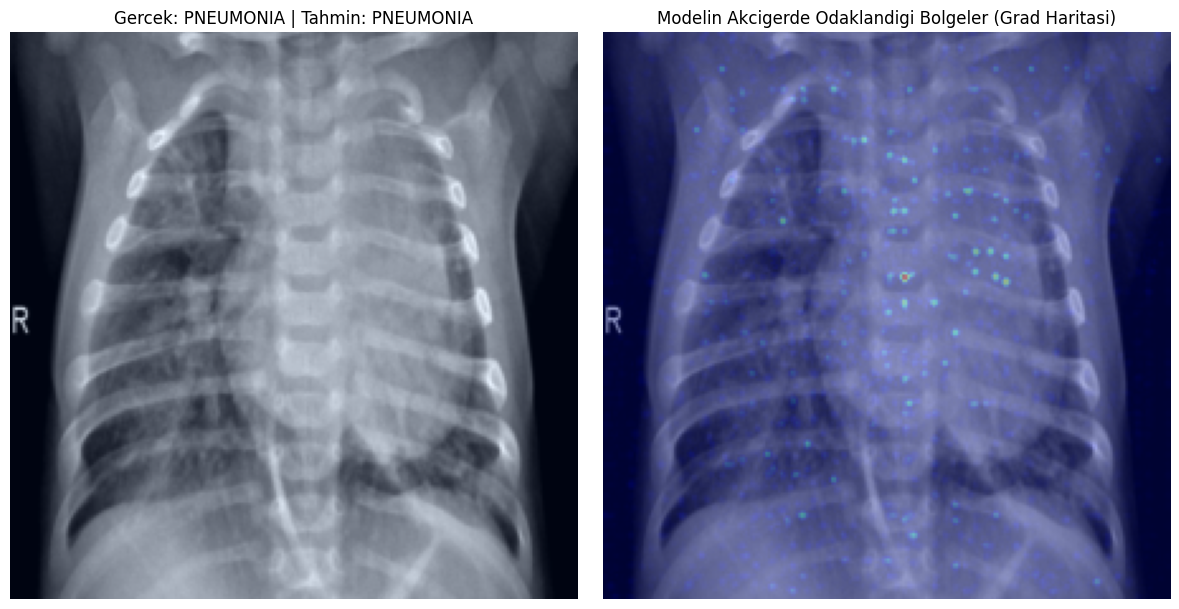

In [ ]:
# Final plot (name error fully fixed)
classes = {0: 'NORMAL', 1: 'PNEUMONIA'}
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title(f"True: {classes[true_label]} | Predicted: {classes[pred_label]}", fontsize=12)
plt.imshow(rgb_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Regions the Model Focuses on in the Lungs (Gradient Saliency Map)", fontsize=12)
plt.imshow(custom_visualization) # Correct variable name used
plt.axis('off')

plt.tight_layout()
plt.show()

Test Accuracy: 87.98%
ROC-AUC: 0.9505

              precision    recall  f1-score   support

      NORMAL      0.896     0.769     0.828       234
   PNEUMONIA      0.872     0.946     0.908       390

    accuracy                          0.880       624
   macro avg      0.884     0.858     0.868       624
weighted avg      0.881     0.880     0.878       624



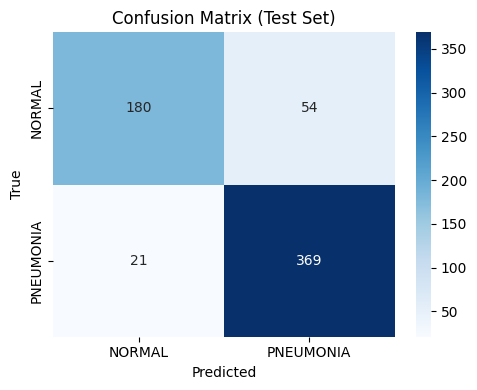


| Epochs | Test Acc | PNEUMONIA Recall | PNEUMONIA Precision | NORMAL Recall | ROC-AUC |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 10 | 87.98% | 0.946 | 0.872 | 0.769 | 0.950 |


In [ ]:
class_names = ["NORMAL", "PNEUMONIA"]

y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(current_device))
        y_prob.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().tolist())
        y_pred.extend(outputs.argmax(dim=1).cpu().tolist())
        y_true.extend(labels.tolist())

acc = np.mean(np.array(y_true) == np.array(y_pred))
auc = roc_auc_score(y_true, y_prob)
print(f"Test Accuracy: {100 * acc:.2f}%")
print(f"ROC-AUC: {auc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()